<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_27.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Test accuracy (model): [0.20606787502765656, 0.9319999814033508]
2D representation via t-SNE on layer features:


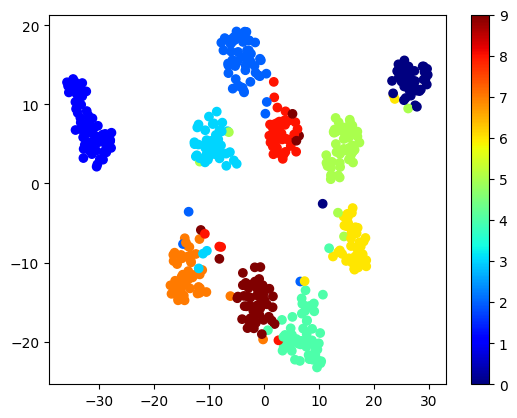

In [2]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
(x,y),(xt,yt)=tf.keras.datasets.mnist.load_data(); x=x.reshape(-1,784).astype('float32')/255; xt=xt.reshape(-1,784).astype('float32')/255

# Using Functional API instead of Sequential to ensure input/output tensors are registered correctly
inputs = tf.keras.layers.Input((784,))
h1 = tf.keras.layers.Dense(500, activation='relu')(inputs)
h2 = tf.keras.layers.Dense(250, activation='relu')(h1)
outputs = tf.keras.layers.Dense(10, activation='softmax')(h2)
a = tf.keras.Model(inputs=inputs, outputs=outputs)

a.compile('adam','sparse_categorical_crossentropy',metrics=['accuracy']); a.fit(x[:10000],y[:10000],epochs=2,verbose=0)

# To visualize representations, we map to the 2D layer or another bottleneck layer.
# Since you wanted a 2D plot, we can project the intermediate representations using t-SNE, or use a 2D dense layer if visualizing directly.
# Here we extract from the second hidden layer (250 dimensions) and project to 2D using TSNE for actual plotting.
from sklearn.manifold import TSNE

print('Test accuracy (model):', a.evaluate(xt[:2000], yt[:2000], verbose=0)); print('2D representation via t-SNE on layer features:')
emb_model = tf.keras.Model(inputs=a.input, outputs=h2)
features = emb_model.predict(xt[:500], verbose=0)

# Project to 2D for visualization since the layer has 250 dimensions
emb_2d = TSNE(n_components=2, random_state=42).fit_transform(features)

plt.scatter(emb_2d[:, 0], emb_2d[:, 1], c=yt[:500], cmap='jet')
plt.colorbar()
plt.show()